In [1]:
# CELLA 1 - Setup
!pip install -q shap scikit-learn matplotlib seaborn pandas numpy
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve, classification_report
import warnings; warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize']=(8,5); sns.set_style('whitegrid')

In [2]:
# CELLA 2 - Dataset UCI Breast Cancer Wisconsin
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')
print(f'Campioni: {X.shape[0]}, Feature: {X.shape[1]}')
print(y.value_counts(normalize=True))
X.head()

Campioni: 569, Feature: 30
target
1    0.627417
0    0.372583
Name: proportion, dtype: float64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
# CELLA 3 - Split 70/15/15 STESSO PER TUTTI I MODELLI
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1765, random_state=42, stratify=y_temp)
print(f'Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}')
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
X_val_s = pd.DataFrame(scaler.transform(X_val), columns=X.columns)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns)

Train: (397, 30), Val: (86, 30), Test: (86, 30)


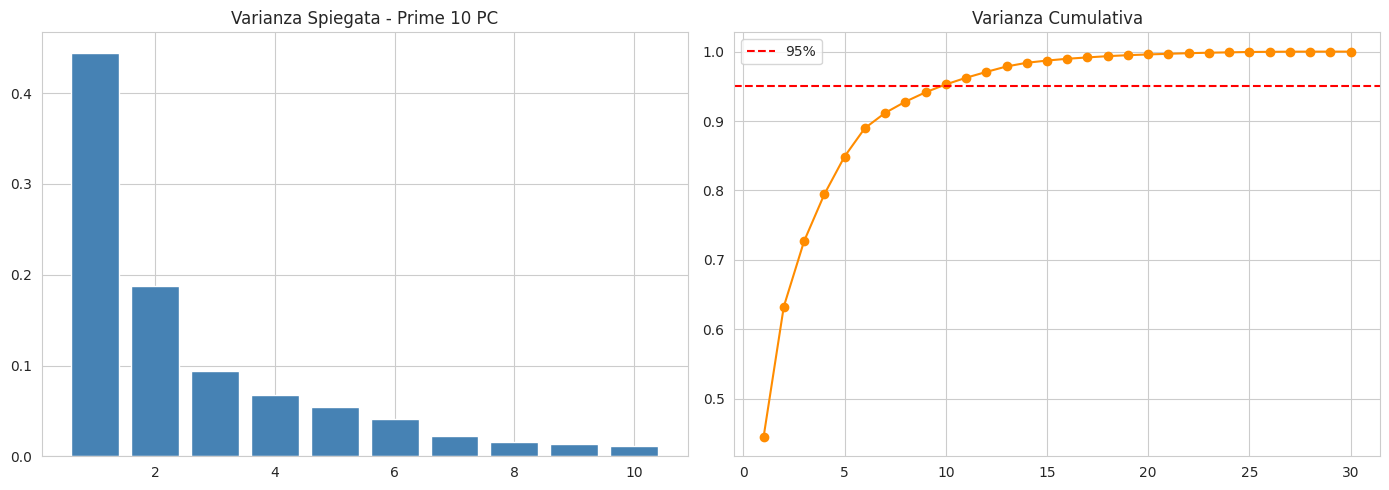

PC per 95%: 10


In [4]:
# CELLA 4 - PCA Varianza spiegata
pca = PCA(); pca.fit(X_train_s)
var_exp = pca.explained_variance_ratio_; cum_var = np.cumsum(var_exp)
fig, ax = plt.subplots(1,2, figsize=(14,5))
ax[0].bar(range(1,11), var_exp[:10], color='steelblue'); ax[0].set_title('Varianza Spiegata - Prime 10 PC')
ax[1].plot(range(1,31), cum_var[:30], marker='o', color='darkorange'); ax[1].axhline(0.95, color='red', linestyle='--', label='95%'); ax[1].set_title('Varianza Cumulativa'); ax[1].legend()
plt.tight_layout(); plt.show()
print(f'PC per 95%: {np.argmax(cum_var>=0.95)+1}')

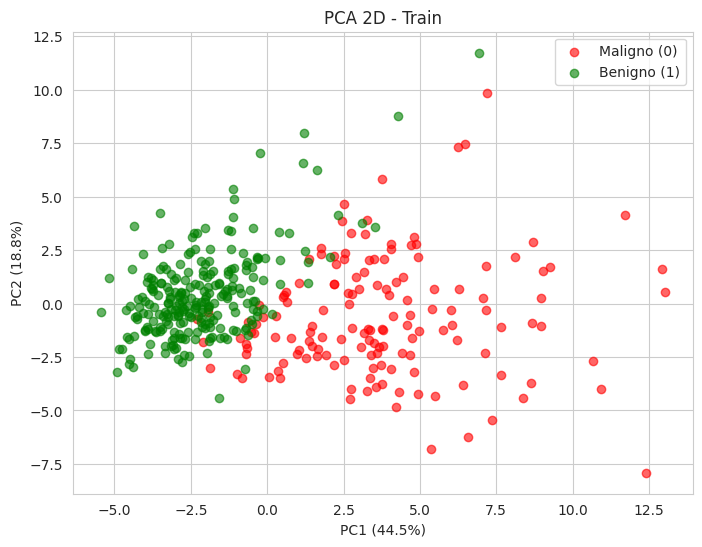

mean concave points     0.260922
mean concavity          0.258011
worst concave points    0.249808
mean compactness        0.240993
worst perimeter         0.233543
worst concavity         0.230530
mean perimeter          0.225397
worst radius            0.224988
worst area              0.221381
mean area               0.218322
dtype: float64


In [5]:
# CELLA 5 - PCA 2D Scatter
pca2 = PCA(n_components=2); X_train_2d = pca2.fit_transform(X_train_s)
plt.figure(figsize=(8,6))
for label, color, name in [(0,'red','Maligno (0)'), (1,'green','Benigno (1)')]:
    mask = y_train==label
    plt.scatter(X_train_2d[mask,0], X_train_2d[mask,1], alpha=0.6, c=color, label=name)
plt.xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)'); plt.ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)'); plt.title('PCA 2D - Train'); plt.legend(); plt.show()
loadings = pd.Series(pca2.components_[0], index=X.columns).sort_values(key=abs, ascending=False)
print(loadings.head(10))

In [6]:
# CELLA 6 - 3 Classificatori
models = {'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42), 'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1), 'SVM (RBF)': SVC(kernel='rbf', C=1.0, probability=True, random_state=42)}
for name, m in models.items():
    m.fit(X_train_s, y_train); print(f'{name} addestrato')

Logistic Regression addestrato
Random Forest addestrato
SVM (RBF) addestrato



=== Logistic Regression ===
              precision    recall  f1-score   support

     Maligno       0.94      0.97      0.95        32
     Benigno       0.98      0.96      0.97        54

    accuracy                           0.97        86
   macro avg       0.96      0.97      0.96        86
weighted avg       0.97      0.97      0.97        86


=== Random Forest ===
              precision    recall  f1-score   support

     Maligno       0.86      0.94      0.90        32
     Benigno       0.96      0.91      0.93        54

    accuracy                           0.92        86
   macro avg       0.91      0.92      0.91        86
weighted avg       0.92      0.92      0.92        86


=== SVM (RBF) ===
              precision    recall  f1-score   support

     Maligno       0.94      0.97      0.95        32
     Benigno       0.98      0.96      0.97        54

    accuracy                           0.97        86
   macro avg       0.96      0.97      0.96        86
wei

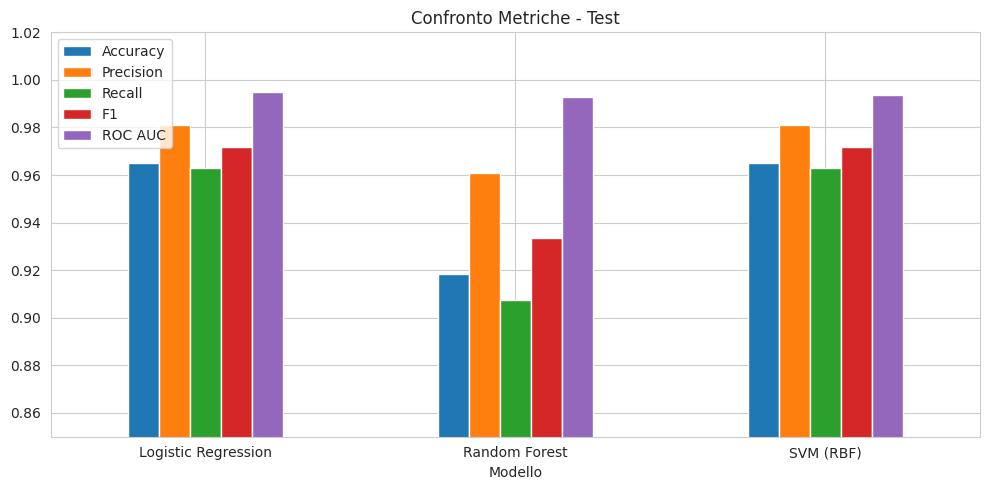

In [7]:
# CELLA 7 - Metriche Test
results=[]
for name, m in models.items():
    y_pred=m.predict(X_test_s); y_proba=m.predict_proba(X_test_s)[:,1]
    results.append({'Modello':name,'Accuracy':accuracy_score(y_test,y_pred),'Precision':precision_score(y_test,y_pred),'Recall':recall_score(y_test,y_pred),'F1':f1_score(y_test,y_pred),'ROC AUC':roc_auc_score(y_test,y_proba)})
    print(f'\n=== {name} ==='); print(classification_report(y_test,y_pred,target_names=['Maligno','Benigno']))
results_df=pd.DataFrame(results).set_index('Modello'); print(results_df.round(4))
results_df.plot(kind='bar', figsize=(10,5), rot=0); plt.title('Confronto Metriche - Test'); plt.ylim(0.85,1.02); plt.tight_layout(); plt.show()

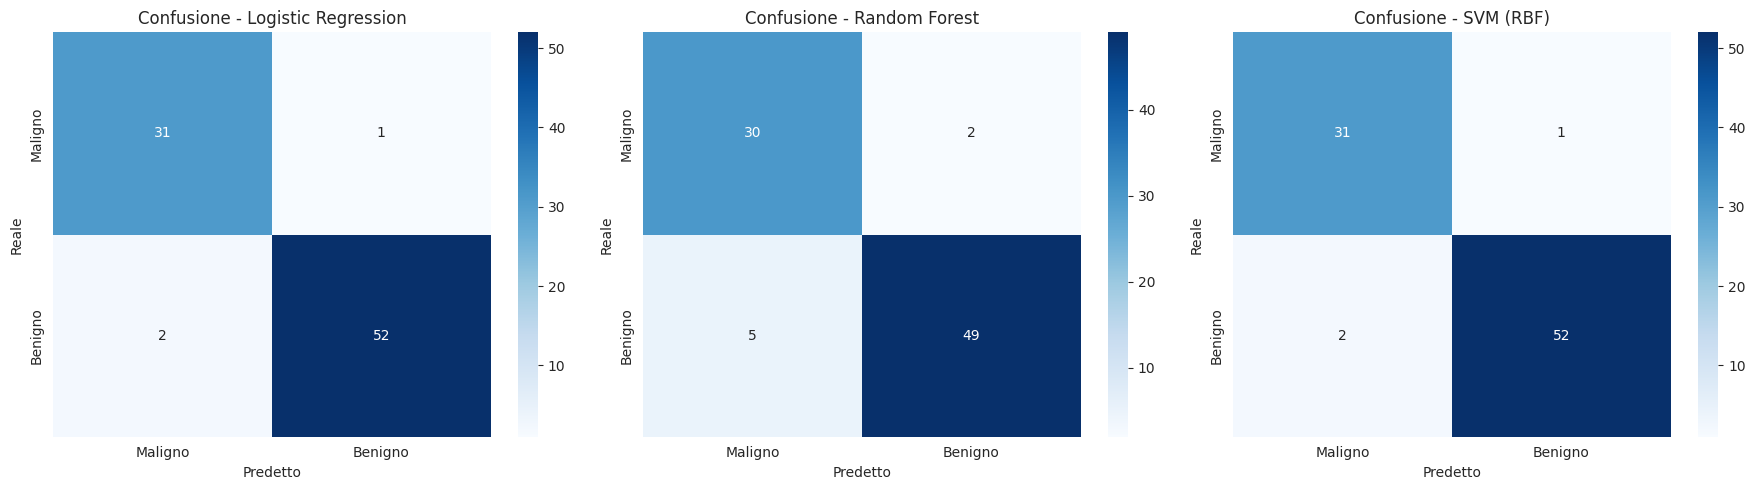

In [8]:
# CELLA 8 - Matrici di Confusione
fig, axes = plt.subplots(1,3, figsize=(18,5))
for ax,(name,m) in zip(axes, models.items()):
    cm=confusion_matrix(y_test, m.predict(X_test_s))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, xticklabels=['Maligno','Benigno'], yticklabels=['Maligno','Benigno'])
    ax.set_title(f'Confusione - {name}'); ax.set_xlabel('Predetto'); ax.set_ylabel('Reale')
plt.tight_layout(); plt.show()

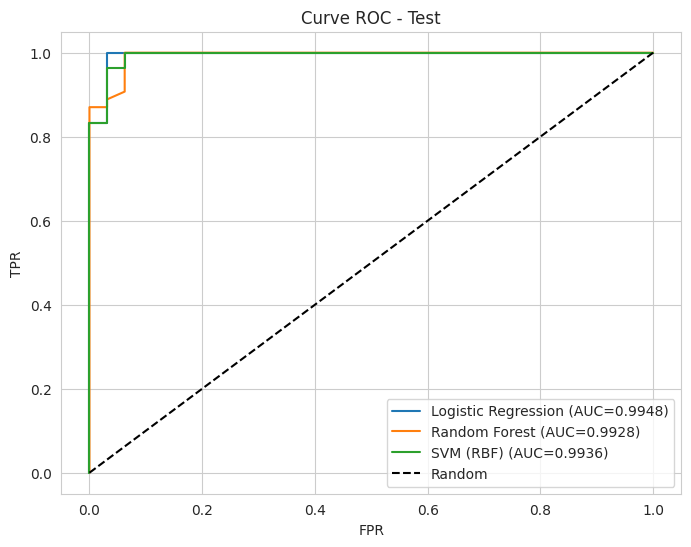

In [9]:
# CELLA 9 - Curve ROC
plt.figure(figsize=(8,6))
for name,m in models.items():
    y_proba=m.predict_proba(X_test_s)[:,1]; fpr,tpr,_=roc_curve(y_test,y_proba); auc=roc_auc_score(y_test,y_proba)
    plt.plot(fpr,tpr,label=f'{name} (AUC={auc:.4f})')
plt.plot([0,1],[0,1],'k--',label='Random'); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('Curve ROC - Test'); plt.legend(); plt.grid(True); plt.show()

In [10]:
# CELLA 10 - SHAP
import shap
best_model=models['Random Forest']
explainer=shap.TreeExplainer(best_model)
shap_values=explainer.shap_values(X_test_s)
try:
    sv=shap_values[1] if isinstance(shap_values,list) else shap_values[:,:,1]
except:
    sv=shap_values
print('Shape SHAP:', np.array(sv).shape)

Shape SHAP: (86, 30)


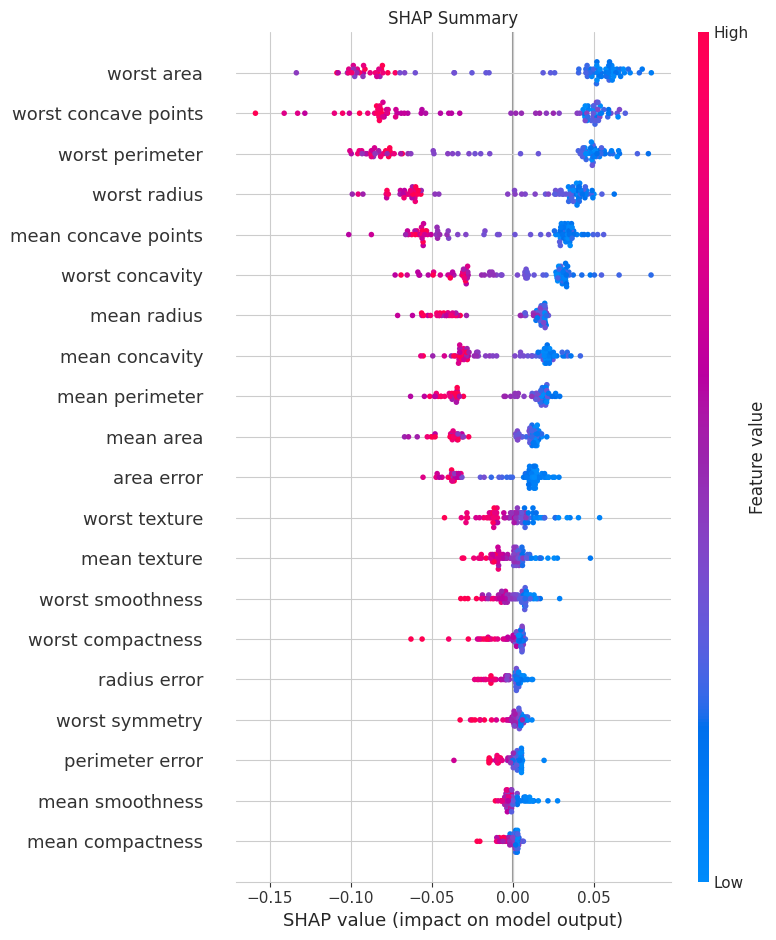

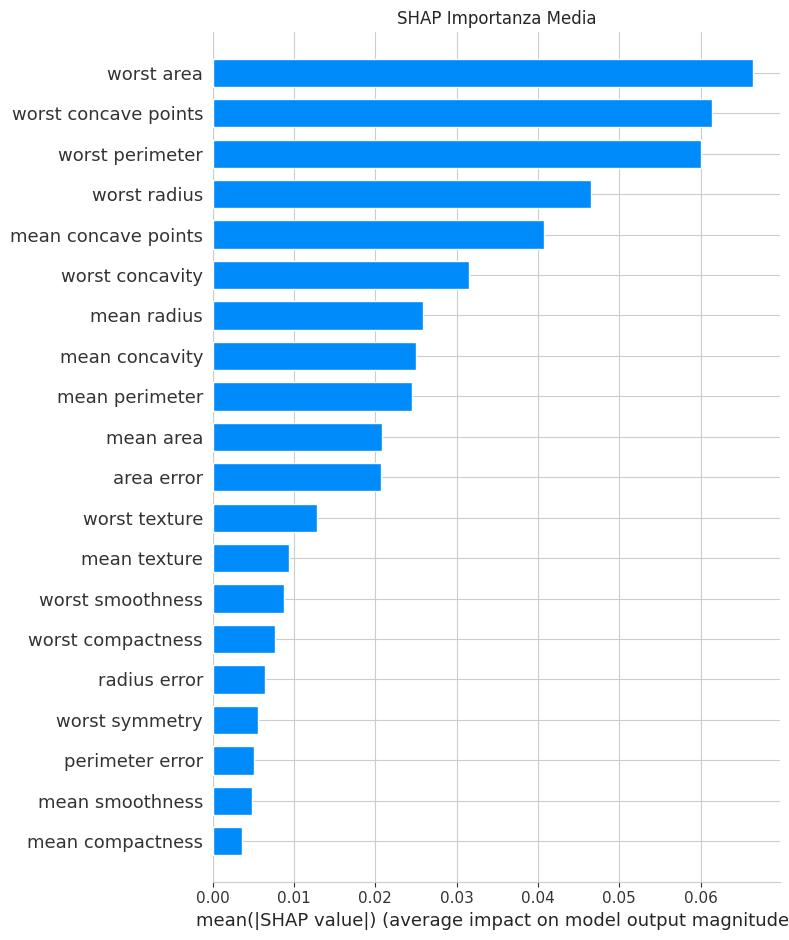

In [11]:
# CELLA 11 - SHAP Plots
shap.summary_plot(sv, X_test_s, show=False); plt.title('SHAP Summary'); plt.tight_layout(); plt.show()
shap.summary_plot(sv, X_test_s, plot_type='bar', show=False); plt.title('SHAP Importanza Media'); plt.tight_layout(); plt.show()

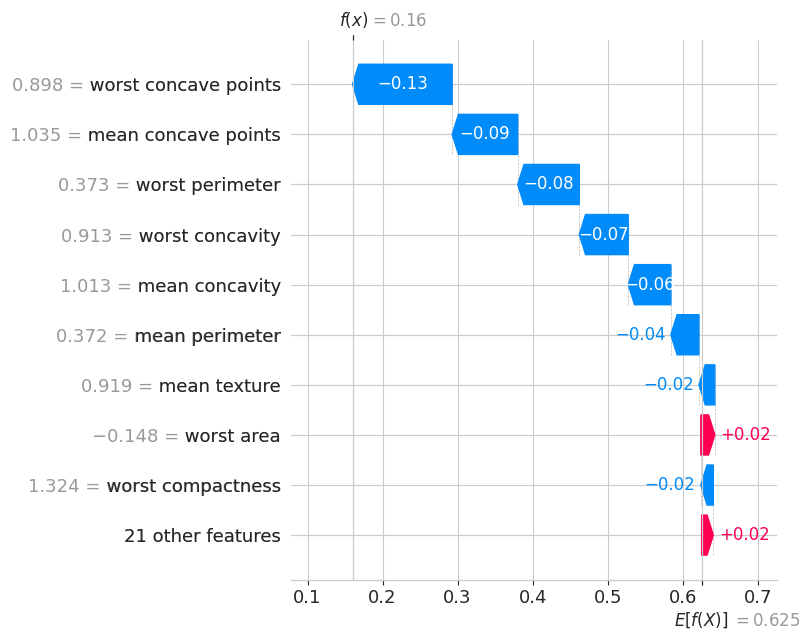

In [12]:
# CELLA 12 - SHAP Waterfall singolo paziente
idx=np.where((y_test.values==0) & (best_model.predict(X_test_s)==0))[0][0]
try:
    exp=shap.Explanation(values=sv[idx], base_values=explainer.expected_value[1], data=X_test_s.iloc[idx], feature_names=list(X.columns))
    shap.waterfall_plot(exp, show=False)
except Exception as e:
    print(e); shap.force_plot(explainer.expected_value[1], sv[idx], X_test_s.iloc[idx], matplotlib=True)
plt.tight_layout(); plt.show()

In [13]:
# CELLA 13 - Confronto importanze
importances=pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print('Top 10 RF:'); print(importances.head(10))
shap_mean=pd.Series(np.abs(sv).mean(axis=0), index=X.columns).sort_values(ascending=False)
print('Top 10 SHAP:'); print(shap_mean.head(10))

Top 10 RF:
worst area              0.125750
worst concave points    0.123770
worst perimeter         0.123581
mean concave points     0.095592
worst radius            0.088802
mean radius             0.059516
mean perimeter          0.055932
mean concavity          0.054321
worst concavity         0.045818
mean area               0.037916
dtype: float64
Top 10 SHAP:
worst area              0.066439
worst concave points    0.061351
worst perimeter         0.060105
worst radius            0.046464
mean concave points     0.040702
worst concavity         0.031521
mean radius             0.025895
mean concavity          0.025006
mean perimeter          0.024525
mean area               0.020855
dtype: float64
